3.1 Hybrid system

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# 1. Parameters and Initial Conditions
# Motor parameters
r_m = 0.006
L_m = 0.003
R_m = 1.5
J_m = 5e-5
K_m = 0.1
m = 0.5
# Nozzle parameters
L_n = 0.01   
C_n = 0.001       
C_tn = 10.0       
# Nozzle parameters
R_n = 14.4    
R_tn = 12.0          
Te = 300.0        
T_target = 550 
# Simulation parameters
dt = 0.0001     
t = 0.0
# Wipe location
xp = 0.0          
yp = 0.0         
u_hold = np.sqrt(R_n * (T_target - Te) / R_tn)
u_heat = 18.0
u_off = 0.0

In [3]:
# Initial motion states
x_x = np.array([0.0, 0.08, 0.0])
x_y = np.array([0.0, 0.0, 0.0])
# Initial nozzle states
Vc0 = np.sqrt(R_n * (T_target - Te) / R_tn)
in0 = Vc0 / R_n
x_n = np.array([T_target, Vc0, in0])
# Combined continuous state
X = np.concatenate((x_x, x_y, x_n))

In [4]:
# 2.1 Motion Dynamics
# Friction coefficients
mu_x = 10.0
mu_y = 10.0
# Effective inertia
M_eff = m + 2 * J_m / r_m**2
# Motor acceleration coefficient
motor_gain = r_m * K_m / (2 * J_m + m * r_m**2)
# Back EMF
back_emf_gain = -2 * K_m / (r_m * L_m)
# State-space matrices
A_x = np.array([
    [-mu_x / M_eff, 0, motor_gain],
    [1, 0, 0],
    [back_emf_gain, 0, -R_m / L_m]
])
A_y = np.array([
    [-mu_y / M_eff, 0, motor_gain],
    [1, 0, 0],
    [back_emf_gain, 0, -R_m / L_m]
])
B = np.array([0, 0, 1 / L_m])
print("A_x =\n", A_x)
print("A_y =\n", A_y)
print("B =", B)

A_x =
 [[-3.05084746e+00  0.00000000e+00  5.08474576e+00]
 [ 1.00000000e+00  0.00000000e+00  0.00000000e+00]
 [-1.11111111e+04  0.00000000e+00 -5.00000000e+02]]
A_y =
 [[-3.05084746e+00  0.00000000e+00  5.08474576e+00]
 [ 1.00000000e+00  0.00000000e+00  0.00000000e+00]
 [-1.11111111e+04  0.00000000e+00 -5.00000000e+02]]
B = [  0.           0.         333.33333333]


In [5]:
# 2.3 Combined Continuous Model
def sys(X, u):
    # Motion states
    x_x = X[0:3]
    x_y = X[3:6]
    # Nozzle states
    Tn, Vc, i_n = X[6:9]
    # Inputs
    ux, uy, un = u
    # Motion dynamics
    dx_x = A_x @ x_x + B * ux
    dx_y = A_y @ x_y + B * uy
    # Nozzle dynamics
    dTn = (Vc**2 / R_n - (Tn - Te) / R_tn) / C_tn
    dVc = (i_n - Vc / R_n) / C_n
    di_n = (un - Vc) / L_n
    # Combined state derivative
    dX = np.concatenate((dx_x, dx_y, [dTn, dVc, di_n]))
    return dX

In [6]:
# 3.1 Events and thresholds
# Filament replacement events
C = False      
F = False       
# Completion events
wipe_done = False
filament_loaded = False
# Position and velocity tolerances
position_tol = 0.001    
velocity_tol = 0.001   
# Nozzle temperature thresholds
T_ready = 547.0
T_safe = 350.0       

In [7]:
# 3.2 Position Guards
def at_position(X, target):
    if target is None:
        return False
    position_error = np.sqrt((X[1] - target[0])**2 +(X[4] - target[1])**2)
    speed = np.sqrt(X[0]**2 + X[3]**2)
    return (position_error <= position_tol
            and speed <= velocity_tol)

In [8]:
# 3.3 Invariants
def check_invariant(X, mode, record):
    if mode == "P":
        return not (C or F)
    elif mode == "MW":
        return not at_position(X, [xp, yp])
    elif mode == "W":
        return not wipe_done
    elif mode == "L":
        return not filament_loaded
    elif mode == "H":
        return X[6] <= T_ready
    elif mode == "R":
        return not at_position(X, record["saved_position"])
    return False

In [9]:
# 3.4 Reset Maps
# Information saved during filament replacement
record = {
    "saved_position": None,
    "saved_progress": 0.0,
    "progress": 0.0,
    "filament_color": "Red",
    "next_color": "Green"
}

In [10]:
def reset_map(old_mode, new_mode, X, record):
    # Continuous states do not jump
    X_new = X.copy()
    # Printing -> Moving to Wipe
    if old_mode == "P" and new_mode == "MW":
        record["saved_position"] = np.array([X[1], X[4]])
        record["saved_progress"] = record["progress"]
    # Loading -> Heating
    elif old_mode == "L" and new_mode == "H":
        record["filament_color"] = record["next_color"]
    # Returning -> Printing
    elif old_mode == "R" and new_mode == "P":
        record["progress"] = record["saved_progress"]
    return X_new, record

In [11]:
# 4.1 Motion control parameters
Kp = 25.0
Kd = 10.0
motor_voltage_limit = 12.0  # V, assumed

In [18]:
# 4.1 Motion controller
def motion_control(X, target):
    x_target, y_target = target
    ax_cmd = Kp * (x_target - X[1]) - Kd * X[0]
    ay_cmd = Kp * (y_target - X[4]) - Kd * X[3]
    ix_target = (ax_cmd + mu_x / M_eff * X[0]) / motor_gain
    iy_target = (ay_cmd + mu_y / M_eff * X[3]) / motor_gain
    ux = R_m * ix_target + 2 * K_m * X[0] / r_m
    uy = R_m * iy_target + 2 * K_m * X[3] / r_m
    u_left = np.clip((ux + uy) / 2, -motor_voltage_limit, motor_voltage_limit)
    u_right = np.clip((ux - uy) / 2, -motor_voltage_limit, motor_voltage_limit)
    return u_left + u_right, u_left - u_right

In [19]:
# 4.2 Heating control
def heating_control(mode):
    if mode == "L":
        return u_off
    elif mode == "H":
        return u_heat
    else:
        return u_hold

In [20]:
# 5.2 Printing Trajectory and Control
# 5.2.1 Printing trajectory parameters
a_print = 0.08      
b_print = 0.05      
omega_print = 0.30   
# Reference trajectory
def print_reference(t_print):
    theta = omega_print * t_print
    # Reference position
    x_ref = a_print * np.cos(theta)
    y_ref = b_print * np.sin(theta)
    # Reference velocity
    vx_ref = -a_print * omega_print * np.sin(theta)
    vy_ref = b_print * omega_print * np.cos(theta)
    return x_ref, y_ref, vx_ref, vy_ref
# 5.2.2 Printing trajectory controller
def printing_control(X, t_print):
    # Reference position and velocity
    x_ref, y_ref, vx_ref, vy_ref = print_reference(t_print)
    # Reference acceleration
    ax_ref = -omega_print**2 * x_ref
    ay_ref = -omega_print**2 * y_ref
    # Desired acceleration in x direction
    ax_cmd = (ax_ref+ Kp * (x_ref - X[1])+ Kd * (vx_ref - X[0]))
    # Desired acceleration in y direction
    ay_cmd = (ay_ref+ Kp * (y_ref - X[4])+ Kd * (vy_ref - X[3]))
    # Required equivalent currents
    ix_target = (ax_cmd + mu_x / M_eff * X[0]) / motor_gain
    iy_target = (ay_cmd + mu_y / M_eff * X[3]) / motor_gain
    # Equivalent motor inputs
    ux = R_m * ix_target + 2 * K_m * X[0] / r_m
    uy = R_m * iy_target + 2 * K_m * X[3] / r_m
    # Left and right motor voltages
    u_left = (ux + uy) / 2
    u_right = (ux - uy) / 2
    # Apply voltage limits
    u_left = np.clip(u_left, -motor_voltage_limit, motor_voltage_limit)
    u_right = np.clip(u_right, -motor_voltage_limit, motor_voltage_limit)
    # Convert back to equivalent inputs
    ux = u_left + u_right
    uy = u_left - u_right
    return ux, uy
# 5.2.3 Printing progress update
def update_print_progress(record, dt):
    record["print_time"] += dt
    record["progress"] = (omega_print * record["print_time"])

In [22]:
# 5.3 Integrated Hybrid Simulation
# 5.3.1 Initialize simulation
dt = 0.0001
t_end = 150.0
t_sim = 0.0
X_sim = X.copy()
mode_sim = "P"
sim_record = record.copy()
sim_record["saved_position"] = None
sim_record["saved_progress"] = 0.0
sim_record["progress"] = 0.0
sim_record["print_time"] = 0.0
sim_record["filament_color"] = "Red"
sim_record["next_color"] = "Green"
# Event settings
change_time = 2.0
change_triggered = False
C = False
F = False
wipe_done = False
filament_loaded = False
wipe_duration = 2.0
loading_duration = 10.0
wipe_elapsed = 0.0
loading_elapsed = 0.0
# 5.3.2 Initialize simulation histories
time_history = [t_sim]
x_history = [X_sim[1]]
y_history = [X_sim[4]]
vx_history = [X_sim[0]]
vy_history = [X_sim[3]]
temperature_history = [X_sim[6]]
mode_history = [mode_sim]
progress_history = [sim_record["progress"]]
print_time_history = [sim_record["print_time"]]
transition_history = [(t_sim, mode_sim)]
# 5.3.3 Main simulation loop
for k in range(int(t_end / dt)):
    # Trigger colour change during printing
    if mode_sim == "P" and not change_triggered:
        if t_sim >= change_time:
            C = True
            change_triggered = True
    # P -> MW
    if mode_sim == "P" and (C or F):
        X_sim, sim_record = reset_map(
            "P", "MW", X_sim, sim_record
        )
        mode_sim = "MW"
        C = False
        F = False
        transition_history.append((t_sim, mode_sim))
    # Select motion controller
    if mode_sim == "P":
        ux, uy = printing_control(
            X_sim, sim_record["print_time"]
        )
    elif mode_sim == "R":
        ux, uy = motion_control(
            X_sim, sim_record["saved_position"]
        )
    else:
        ux, uy = motion_control(
            X_sim, [xp, yp]
        )
    # Nozzle heating controller
    un = heating_control(mode_sim)
    # Combined control input
    u_sim = np.array([ux, uy, un])
    # Update continuous dynamics
    X_sim = X_sim + dt * sys(X_sim, u_sim)
    t_sim += dt
    # Update printing progress
    if mode_sim == "P":
        update_print_progress(sim_record, dt)
    # Update wiping timer
    elif mode_sim == "W":
        wipe_elapsed += dt
    # Update loading timer
    elif mode_sim == "L":
        loading_elapsed += dt
    # MW -> W
    if mode_sim == "MW" and at_position(X_sim, [xp, yp]):
        X_sim, sim_record = reset_map(
            "MW", "W", X_sim, sim_record
        )
        mode_sim = "W"
        wipe_elapsed = 0.0
        transition_history.append((t_sim, mode_sim))
    # W -> L
    elif mode_sim == "W" and wipe_elapsed >= wipe_duration:
        wipe_done = True
        X_sim, sim_record = reset_map(
            "W", "L", X_sim, sim_record
        )
        mode_sim = "L"
        wipe_done = False
        loading_elapsed = 0.0
        transition_history.append((t_sim, mode_sim))
    # L -> H
    elif mode_sim == "L" and loading_elapsed >= loading_duration:
        filament_loaded = True
        X_sim, sim_record = reset_map(
            "L", "H", X_sim, sim_record
        )
        mode_sim = "H"
        filament_loaded = False
        transition_history.append((t_sim, mode_sim))
    # H -> R
    elif mode_sim == "H" and X_sim[6] >= T_ready:
        X_sim, sim_record = reset_map(
            "H", "R", X_sim, sim_record
        )
        mode_sim = "R"
        transition_history.append((t_sim, mode_sim))
    # R -> P
    elif mode_sim == "R" and at_position(
        X_sim, sim_record["saved_position"]
    ):
        X_sim, sim_record = reset_map(
            "R", "P", X_sim, sim_record
        )
        mode_sim = "P"
        transition_history.append((t_sim, mode_sim))
    # Record results every 100 steps
    if (k + 1) % 100 == 0:
        time_history.append(t_sim)
        x_history.append(X_sim[1])
        y_history.append(X_sim[4])
        vx_history.append(X_sim[0])
        vy_history.append(X_sim[3])
        temperature_history.append(X_sim[6])
        mode_history.append(mode_sim)
        progress_history.append(sim_record["progress"])
        print_time_history.append(sim_record["print_time"])
    # Stop after completing one ellipse
    if mode_sim == "P" and sim_record["progress"] >= 2 * np.pi:
        break
# 5.3.4 Record final state
time_history.append(t_sim)
x_history.append(X_sim[1])
y_history.append(X_sim[4])
vx_history.append(X_sim[0])
vy_history.append(X_sim[3])
temperature_history.append(X_sim[6])
mode_history.append(mode_sim)
progress_history.append(sim_record["progress"])
print_time_history.append(sim_record["print_time"])
# 5.3.5 Simulation results
print("Final mode:", mode_sim)
print("Total simulation time:", t_sim)
print("Final position:", X_sim[1], X_sim[4])
print("Final nozzle temperature:", X_sim[6])
print("Final filament color:", sim_record["filament_color"])
print("Printing progress:", sim_record["progress"])
print("One ellipse completed:",
      sim_record["progress"] >= 2 * np.pi)
print("\nFSM transitions:")
for t, q in transition_history:
    print(f"{t:.3f} s : {q}")

Final mode: P
Total simulation time: 102.39240000227554
Final position: 0.08000190252956997 7.05297812316245e-07
Final nozzle temperature: 547.4719469601598
Final filament color: Green
Printing progress: 6.283199999989359
One ellipse completed: True

FSM transitions:
0.000 s : P
2.000 s : MW
3.586 s : W
5.586 s : L
15.586 s : H
81.859 s : R
83.449 s : P


In [23]:
# 5.4 Plot settings
plt.rcParams.update({
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "legend.fontsize": 9,
    "figure.dpi": 120,
    "axes.spines.top": False,
    "axes.spines.right": False
})
# Consistent colors
red_color = "#C44E52"
green_color = "#24866D"
blue_color = "#3579B5"
gray_color = "#858D98"
# Convert histories to arrays
t = np.array(time_history)
x = np.array(x_history)
y = np.array(y_history)
T = np.array(temperature_history)
progress = np.array(progress_history)
# Important transition times
t_pause = next(v for v, q in transition_history if q == "MW")
t_wipe = next(v for v, q in transition_history if q == "W")
t_loading = next(v for v, q in transition_history if q == "L")
t_heating = next(v for v, q in transition_history if q == "H")
t_return = next(v for v, q in transition_history if q == "R")
t_resume = [v for v, q in transition_history if q == "P"][-1]

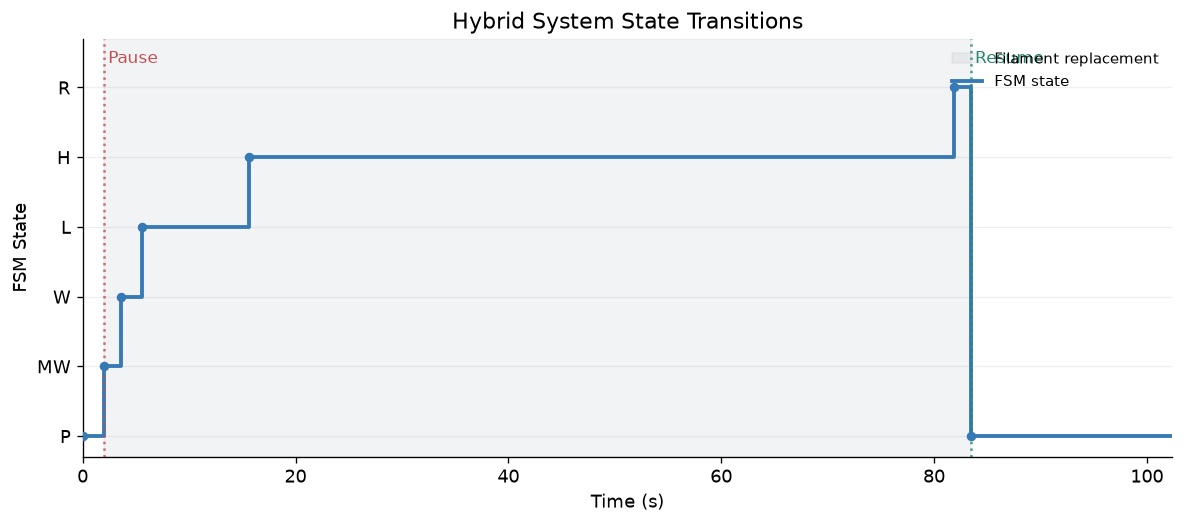

In [24]:
# 5.4.1 FSM State Transitions
state_numbers = {
    "P": 0,
    "MW": 1,
    "W": 2,
    "L": 3,
    "H": 4,
    "R": 5
}
transition_times = [v for v, q in transition_history] + [t_sim]
transition_modes = [q for v, q in transition_history] + [mode_sim]
state_values = [state_numbers[q] for q in transition_modes]
fig, ax = plt.subplots(figsize=(10, 4.5))
# Highlight filament replacement
ax.axvspan(
    t_pause, t_resume,
    color=gray_color, alpha=0.10,
    label="Filament replacement"
)
# FSM transitions
ax.step(
    transition_times, state_values,
    where="post",
    color=blue_color, linewidth=2.3,
    label="FSM state"
)
# Transition points
ax.scatter(
    transition_times[:-1],
    state_values[:-1],
    color=blue_color, s=22, zorder=4
)
# Pause and resume times
ax.axvline(t_pause, color=red_color,
           linestyle=":", alpha=0.8)
ax.axvline(t_resume, color=green_color,
           linestyle=":", alpha=0.8)
ax.text(t_pause + 0.4, 5.35, "Pause",
        color=red_color, fontsize=10)
ax.text(t_resume + 0.4, 5.35, "Resume",
        color=green_color, fontsize=10)
ax.set_yticks(
    list(state_numbers.values()),
    ["P", "MW", "W", "L", "H", "R"]
)
ax.set_ylim(-0.3, 5.7)
ax.set_xlim(0, t_sim)
ax.set_xlabel("Time (s)")
ax.set_ylabel("FSM State")
ax.set_title("Hybrid System State Transitions")
ax.grid(axis="y", alpha=0.2)
ax.legend(frameon=False, loc="upper right")
plt.tight_layout()
plt.show()

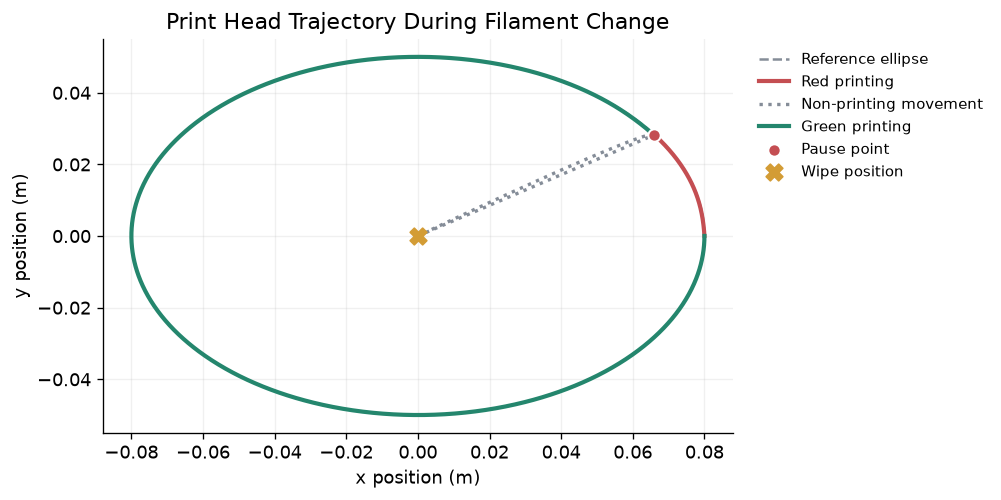

In [25]:
# 5.4.2 Print Head Trajectory
theta = np.linspace(0, 2*np.pi, 500)
x_ref = a_print * np.cos(theta)
y_ref = b_print * np.sin(theta)
fig, ax = plt.subplots(figsize=(8.5, 5.5))
# Reference ellipse
ax.plot(
    x_ref, y_ref,
    color=gray_color,
    linestyle="--",
    linewidth=1.5,
    label="Reference ellipse"
)
# Red printing
red_mask = t <= t_pause
ax.plot(
    x[red_mask], y[red_mask],
    color=red_color,
    linewidth=2.5,
    label="Red printing"
)
# Moving to wipe
move_mask = (t >= t_pause) & (t <= t_wipe)
ax.plot(
    x[move_mask], y[move_mask],
    color=gray_color,
    linestyle=":",
    linewidth=2,
    label="Non-printing movement"
)
# Returning to print
return_mask = (t >= t_return) & (t <= t_resume)
ax.plot(
    x[return_mask], y[return_mask],
    color=gray_color,
    linestyle=":",
    linewidth=2
)
# Green printing
green_mask = t >= t_resume
ax.plot(
    x[green_mask], y[green_mask],
    color=green_color,
    linewidth=2.5,
    label="Green printing"
)
# Pause point
pause_index = np.argmin(np.abs(t - t_pause))
ax.scatter(
    x[pause_index], y[pause_index],
    color=red_color,
    s=55, marker="o",
    edgecolors="white",
    linewidths=1.2,
    label="Pause point",
    zorder=5
)
# Wipe position
ax.scatter(
    xp, yp,
    color="#D39C35",
    marker="X", s=100,
    label="Wipe position",
    zorder=5
)
ax.set_xlabel("x position (m)")
ax.set_ylabel("y position (m)")
ax.set_title("Print Head Trajectory During Filament Change")
ax.set_aspect("equal", adjustable="box")
ax.grid(alpha=0.18)
ax.legend(
    loc="upper left",
    bbox_to_anchor=(1.02, 1),
    frameon=False
)
plt.tight_layout()
plt.show()

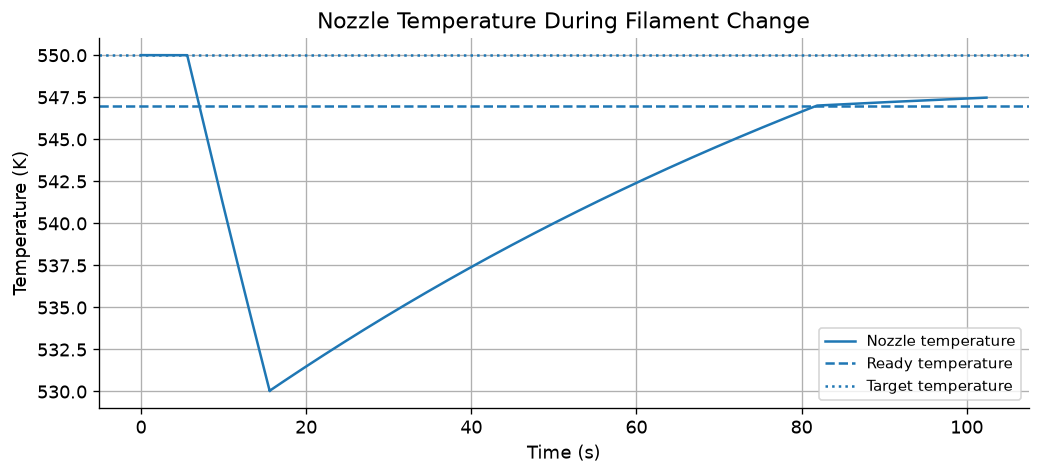

In [26]:
# 5.4.3 Nozzle Temperature
plt.figure(figsize=(10, 4))
plt.plot(
    time_history,
    temperature_history,
    label="Nozzle temperature"
)
plt.axhline(
    T_ready,
    linestyle="--",
    label="Ready temperature"
)
plt.axhline(
    T_target,
    linestyle=":",
    label="Target temperature"
)
plt.xlabel("Time (s)")
plt.ylabel("Temperature (K)")
plt.title("Nozzle Temperature During Filament Change")
plt.legend()
plt.grid(True)
plt.show()

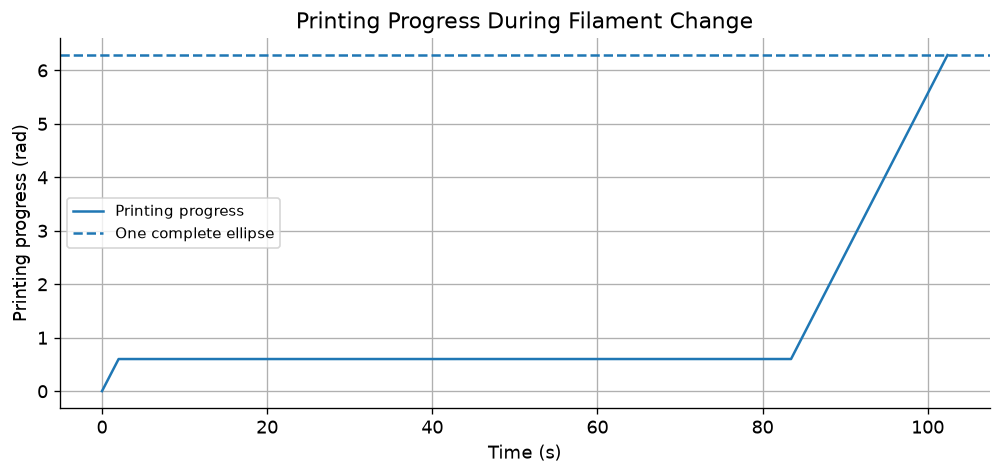

In [27]:
# 5.4.4 Printing Progress
plt.figure(figsize=(10, 4))
plt.plot(
    time_history,
    progress_history,
    label="Printing progress"
)
plt.axhline(
    2 * np.pi,
    linestyle="--",
    label="One complete ellipse"
)
plt.xlabel("Time (s)")
plt.ylabel("Printing progress (rad)")
plt.title("Printing Progress During Filament Change")
plt.legend()
plt.grid(True)
plt.show()

In [28]:
# 5.5 Model Validation
# Convert simulation histories into arrays
t_data = np.array(time_history)
x_data = np.array(x_history)
y_data = np.array(y_history)
T_data = np.array(temperature_history)
p_data = np.array(progress_history)
tp_data = np.array(print_time_history)
mode_data = np.array(mode_history)
# 1. FSM validation
expected_sequence = ["P", "MW", "W", "L", "H", "R", "P"]
actual_sequence = [q for _, q in transition_history]
fsm_valid = actual_sequence == expected_sequence
print("FSM sequence valid:", fsm_valid)
# 2. Trajectory tracking error
theta_ref = omega_print * tp_data
x_ref = a_print * np.cos(theta_ref)
y_ref = b_print * np.sin(theta_ref)
position_error = np.sqrt(
    (x_data - x_ref)**2 +
    (y_data - y_ref)**2
)
# Only evaluate actual printing
printing_mask = mode_data == "P"
printing_error = position_error[printing_mask]
rmse = np.sqrt(np.mean(printing_error**2))
max_error = np.max(printing_error)
print("Trajectory RMSE (mm):", rmse * 1000)
print("Maximum tracking error (mm):", max_error * 1000)
# 3. Printing pause validation
pause_mask = (t_data >= t_pause) & (t_data <= t_resume)
pause_variation = np.ptp(p_data[pause_mask])
print("Progress variation during pause:", pause_variation)
# 4. Thermal validation
print("Minimum nozzle temperature (K):", np.min(T_data))
print("Minimum printing temperature (K):",
      np.min(T_data[printing_mask]))
print("Final nozzle temperature (K):", X_sim[6])
# 5. Final completion checks
print("Ellipse completed:", p_data[-1] >= 2 * np.pi)
print("Final filament color:", sim_record["filament_color"])
print("Finite simulation values:",
      np.all(np.isfinite(X_sim)))

FSM sequence valid: True
Trajectory RMSE (mm): 0.23033087322654053
Maximum tracking error (mm): 1.3329689826726114
Progress variation during pause: 0.0
Minimum nozzle temperature (K): 530.0207301176508
Minimum printing temperature (K): 547.0396637610528
Final nozzle temperature (K): 547.4719469601598
Ellipse completed: True
Final filament color: Green
Finite simulation values: True
